# Lesson 0.3: Your first model

Can we tell a penguin's species from two measurements? We train a small model on most of the penguins, keep some hidden, and test it on those. Run each cell from top to bottom with **Shift + Enter**.

In [1]:
from pathlib import Path
import pandas as pd

# Find the data file, wherever this notebook is opened from
here = Path.cwd()
csv = next(p / "data/penguins/penguins.csv" for p in [here, *here.parents] if (p / "data/penguins/penguins.csv").exists())
df = pd.read_csv(csv)

# Keep the penguins that have both measurements
data = df.dropna(subset=["bill_length_mm", "flipper_length_mm"])
print(len(data), "penguins")

342 penguins


## Look at the data first

Each dot is one penguin. Can you see the groups?

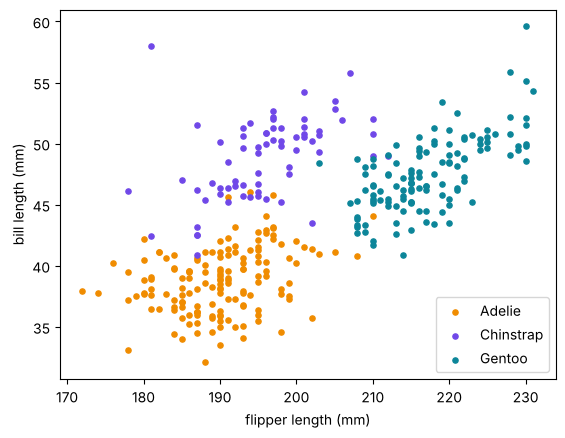

In [2]:
import matplotlib.pyplot as plt

colours = {"Adelie": "#f08c00", "Chinstrap": "#7048e8", "Gentoo": "#0c8599"}
for species, group in data.groupby("species"):
    plt.scatter(group["flipper_length_mm"], group["bill_length_mm"], s=14, label=species, color=colours[species])
plt.xlabel("flipper length (mm)")
plt.ylabel("bill length (mm)")
plt.legend()
plt.show()

## Features and label

The **features** are what we know. The **label** is what we want to predict.

In [3]:
X = data[["bill_length_mm", "flipper_length_mm"]]  # features
y = data["species"]                                 # label

## Keep some penguins hidden for the test

We train on 75% and test on the other 25%. `random_state=42` makes the split the same every time, so your numbers match the lesson.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(len(X_train), "for training,", len(X_test), "hidden for the test")

256 for training, 86 hidden for the test


## Train a small model

A decision tree learns a few yes-or-no rules. `max_depth=2` means at most two questions per penguin.

In [5]:
from sklearn.tree import DecisionTreeClassifier, export_text

model = DecisionTreeClassifier(max_depth=2, random_state=0)
model.fit(X_train, y_train)

print("Training score:", round(model.score(X_train, y_train), 3))
print("Test score:    ", round(model.score(X_test, y_test), 3))

Training score: 0.941
Test score:     0.977


These are the rules the model learned:

In [6]:
print(export_text(model, feature_names=list(X.columns)))

|--- flipper_length_mm <= 206.50
|   |--- bill_length_mm <= 43.35
|   |   |--- class: Adelie
|   |--- bill_length_mm >  43.35
|   |   |--- class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- bill_length_mm <= 41.25
|   |   |--- class: Adelie
|   |--- bill_length_mm >  41.25
|   |   |--- class: Gentoo



## Overfitting

Now let the tree grow as big as it likes. Watch the training score and the test score.

In [7]:
big = DecisionTreeClassifier(random_state=0)
big.fit(X_train, y_train)

print("Training score:", round(big.score(X_train, y_train), 3))
print("Test score:    ", round(big.score(X_test, y_test), 3))
print("Number of rules (leaves):", big.get_n_leaves())

Training score: 1.0
Test score:     0.953
Number of rules (leaves): 26


The big tree is perfect on the penguins it trained on, but does worse than the small tree on the hidden ones. It memorised the training data instead of learning the pattern. That is **overfitting**.

## Try it yourself

Change `max_depth=2` to 1, 3 and 5 and run the cells again. Write down the training and test scores. Which model would you choose?